# 03. Model Training and Cross-Validation

**Objective:** To construct and validate predictive Quantitative Structure-Activity Relationship (QSAR) continuous regression models to predict $pIC_{50}$ binding affinities for Cyclin-Dependent Kinase 2 (CDK2) inhibitors. 

The workflow evaluates two molecular representation techniques (2048-bit Morgan fingerprints vs. global RDKit 2D descriptors) across two regression algorithms (Random Forest and XGBoost Regressors).

**Validation:** Models were tested using 5-fold cross-validation over 3 random seeds, comparing a random split baseline against a scaffold-grouped split strategy.

## 1. Setup and Data Ingestion
Initializes the directory pathways, configures visualization parameters, sets random seeds, and imports the processed dataset generated in the previous workflow.

In [10]:
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, rdFingerprintGenerator

from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import KFold

RDLogger.DisableLog('rdApp.*')
sns.set_theme(style='ticks')


# Path resolution
HERE = Path.cwd()
DATA = HERE.parent / 'data'
FIGURES = HERE.parent / 'figures'
TABLES = HERE.parent / 'results' / 'tables'
TABLES.mkdir(parents=True, exist_ok=True)

SEED = 42
SEEDS = [0, 1, 2]
N_SPLITS = 5

df = pd.read_csv(DATA / 'processed' / 'cdk2_featured.csv')

print("Done")

Done


In [11]:
print(df['split'].value_counts().to_dict())
df.groupby('split')['pIC50'].describe().round(2)

{'train': 1681, 'holdout': 363}


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
holdout,363.0,6.16,1.27,2.91,5.35,6.16,7.07,9.30
train,1681.0,6.53,1.28,2.92,5.68,6.61,7.51,9.52


## 2. Molecular Feature Generation
To evaluate model dependencies on different chemical representations, two distinct feature sets are generated for each molecule:
* **Morgan Fingerprints:** 2048-bit structural vectors representing local topological environments with a bond radius of 2.
* **RDKit Descriptors:** A 204-dimensional vector of global physicochemical properties.

Columns containing invariant or missing values ($NaN$/$\infty$) across the training molecules are dropped to keep input data clean.

In [12]:
is_train = (df['split'] == 'train').to_numpy()

mols = [Chem.MolFromSmiles(s) for s in df['std_smiles']]

gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
X_fp = np.array([gen.GetFingerprintAsNumPy(m) for m in mols])

desc = pd.DataFrame([Descriptors.CalcMolDescriptors(m) for m in mols]).astype('float64')
desc = desc.replace([np.inf, -np.inf], np.nan).dropna(axis=1)
desc = desc.loc[:, desc[is_train].std() > 0]
X_desc = desc.to_numpy()

print("Morgan:", X_fp.shape, "| descriptors:", X_desc.shape)

Morgan: (2044, 2048) | descriptors: (2044, 204)


## 3. Cross-Validation Splitting Strategies
To validate model generalizability data is split into 5 cross-validation folds across 3 random seeds using two different grouping methods:
* **Random Split ($KFold$):** Compounds are randomly distributed across folds. Because structural analogues routinely appear on both sides of the split, this provides an over-optimistic performance baseline.
* **Scaffold-grouped Split:** Compounds are clustered by their core Bemis-Murcko skeleton, ensuring entire chemical series are restricted to single folds. This forces the model to predict entirely unseen chemical space, providing a realistic estimate for novel chemistry.


In [13]:
y = df.loc[is_train, 'pIC50'].to_numpy()
groups = df.loc[is_train, 'scaffold'].to_numpy()
n = len(y)

def random_splits(n, seed):
    for fold, (tr, te) in enumerate(KFold(N_SPLITS, shuffle=True, random_state=seed).split(np.arange(n))):
        yield seed, fold, tr, te

def scaffold_splits(groups, seed):
    """
    Scaffold Split Generator: Ensures entire scaffolds are kept together in same fold.
    """
    rng = np.random.default_rng(seed)
    unique = rng.permutation(pd.unique(groups))
    fold_of = {g: i % N_SPLITS for i, g in enumerate(unique)}
    folds = np.array([fold_of[g] for g in groups])
    for f in range(N_SPLITS):
        yield seed, f, np.where(folds != f)[0], np.where(folds == f)[0]

schemes = {
    'random':   [s for seed in SEEDS for s in random_splits(n, seed)],
    'scaffold': [s for seed in SEEDS for s in scaffold_splits(groups, seed)],
}

# Check that no scaffold shared between train and test part of any grouped fold
for _, _, tr, te in schemes['scaffold']:
    assert not set(groups[tr]) & set(groups[te])
print({k: len(v) for k, v in schemes.items()}, 'folds each')

{'random': 15, 'scaffold': 15} folds each


## 4. Cross-Validation Evaluation
This section executes the training loop across all 15 generated splits, training both the Random Forest and XGBoost regressors on each fold.

Hyperparameters for both algorithms are held fixed to ensure a controlled comparison between the feature sets and validation schemes.

In [14]:
#Models
models = {
    'RF':  lambda: RandomForestRegressor(n_estimators=500, n_jobs=-1, random_state=SEED),
    'XGB': lambda: XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6,
                                subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=SEED),
}

# Features
features = {'Morgan': X_fp[is_train], 'RDKit descriptors': X_desc[is_train]}

def cv_scores(make_model, X, y, splits):
    rows = []
    for repeat, fold, tr, te in splits:
        pred = make_model().fit(X[tr], y[tr]).predict(X[te])
        rows.append({'repeat': repeat, 'fold': fold, 'R2': r2_score(y[te], pred),
                     'RMSE': np.sqrt(mean_squared_error(y[te], pred))})
    return pd.DataFrame(rows)

results = []
# Cartesian prodduct of input iterables
for (fname, X), (mname, make), (sname, splits) in itertools.product(
        features.items(), models.items(), schemes.items()):
    r = cv_scores(make, X, y, splits)
    r[['features', 'model', 'scheme']] = fname, mname, sname
    results.append(r)
    print(f"{fname:18s} {mname:4s} {sname:9s} R2={r['R2'].mean():.3f}  RMSE={r['RMSE'].mean():.3f}")

res = pd.concat(results, ignore_index=True)
res.to_csv(TABLES / 'cv_results.csv', index=False)

Morgan             RF   random    R2=0.677  RMSE=0.724
Morgan             RF   scaffold  R2=0.506  RMSE=0.887
Morgan             XGB  random    R2=0.675  RMSE=0.728
Morgan             XGB  scaffold  R2=0.513  RMSE=0.877
RDKit descriptors  RF   random    R2=0.650  RMSE=0.755
RDKit descriptors  RF   scaffold  R2=0.474  RMSE=0.916
RDKit descriptors  XGB  random    R2=0.665  RMSE=0.739
RDKit descriptors  XGB  scaffold  R2=0.502  RMSE=0.892


### 5. Cross-Validation Performance Summary

The evaluation matrix presents the average values calculated across 15 distinct folds (3 seeds $\times$ 5 folds) per configuration. Two trends emerge from these comparisons:

* **The Split Determines the Score:** Random validation splits yield overly optimistic results ($R^2 \approx 0.67$, $RMSE \approx 0.73$). Scaffold-grouped splits lower the baseline ($R^2 \approx 0.51$, $RMSE \approx 0.88$), providing a more realistic estimate for novel chemical space.
* **Feature Representations are Comparable** Morgan fingerprints scored slightly higher than descriptors across all four comparisons (by 0.01 to 0.03 in $R^2$), though this delta falls within the fold-to-fold standard deviation margin (0.02 to 0.10).

**Final Selection: Morgan fingerprints with an XGBoost Regressor** ($R^2_{\text{scaffold}} = 0.513$, $RMSE_{\text{scaffold}} = 0.877$). This configuration's recorded a slightly higher average performance than Random Forest. It captures roughly half the biological variance with an expected error margin of $\approx 0.9$ units, providing a reliable sorting mechanism to prioritize compounds during virtual screening.


In [15]:
summary = (res.groupby(['features', 'model', 'scheme'])[['R2', 'RMSE']]
              .agg(['mean', 'std']).round(3))
summary

R2          RMSE       
                                   mean    std   mean    std
features          model scheme                              
Morgan            RF    random    0.677  0.036  0.724  0.033
                        scaffold  0.506  0.076  0.887  0.065
                  XGB   random    0.675  0.031  0.728  0.029
                        scaffold  0.513  0.105  0.877  0.082
RDKit descriptors RF    random    0.650  0.028  0.755  0.026
                        scaffold  0.474  0.064  0.916  0.060
                  XGB   random    0.665  0.022  0.739  0.022
                        scaffold  0.502  0.053  0.892  0.053

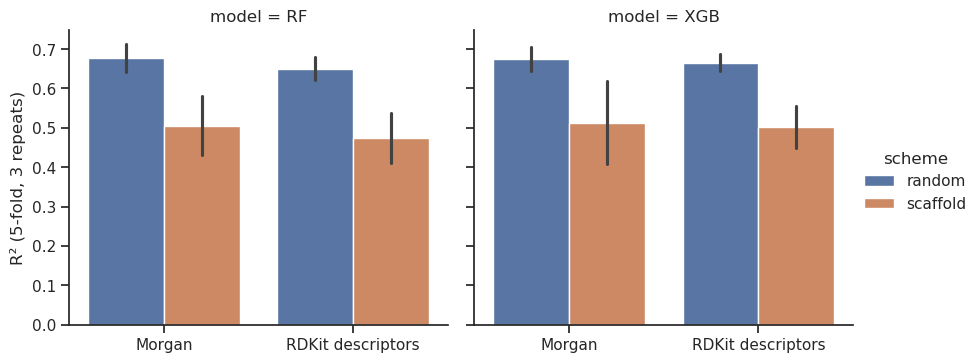

In [16]:
g = sns.catplot(data=res, kind='bar', x='features', y='R2', hue='scheme', col='model',
                errorbar='sd', height=4, aspect=1.1)
g.set_axis_labels('', 'R² (5-fold, 3 repeats)')
plt.savefig(FIGURES / 'cv_random_vs_scaffold.png', dpi=300, bbox_inches='tight')
plt.show()